# A/B Test de Estratégias de Prevenção à Fraude

**Portfólio | Python + Data Analytics + Prevenção à Fraude**

Este notebook demonstra uma avaliação retrospectiva de duas políticas antifraude sobre uma população sintética. O objetivo é transformar um raciocínio operacional de risco, originalmente realizado com Excel, em uma análise reproduzível em Python.

## 1. Contexto de negócio

O projeto foi inspirado em um estudo histórico de Charge Back realizado entre dezembro de 2016 e março de 2017. O relatório registra ataques específicos em bandeiras de cartões com alto valor aquisitivo e aponta problemas de parametrização das ferramentas, falhas humanas e comunicação.

> **Importante:** os resultados deste notebook são produzidos com dados sintéticos. Eles não representam resultados da operação histórica. As regras A e B também são demonstrativas.

## 2. Dados públicos e privacidade

As bases históricas reais analisadas durante o projeto contêm campos potencialmente pessoais ou confidenciais. Por isso, o repositório público não inclui esses arquivos. O dataset em `data/dataset_publico_sintetico.csv` foi criado apenas para demonstrar o método.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
from statsmodels.stats.contingency_tables import mcnemar

pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv('../data/dataset_publico_sintetico.csv')
df.head()

,pedido,valor,hora,score,ip_recorrencia,email_recorrencia,velocidade,sinal_ataque,retira_loja,canal,produto,resultado_real
0,100000,934.08,5,0.7253,2,2,2,0,0,MARKETPLACE,Smartphone,0
1,100001,420.10,8,0.8098,1,1,2,0,0,SITE,Acessório,0
2,100002,232.75,12,0.8400,1,1,2,0,0,MARKETPLACE,Smartphone,0
3,100003,1817.38,20,0.7840,2,2,2,0,0,SITE,Smartphone,0
4,100004,467.59,20,0.8647,2,1,1,0,0,APP,Smartphone,0


In [3]:
print('Linhas:', len(df))
print('Colunas:', len(df.columns))
print('Taxa de fraude sintética:', f"{df['resultado_real'].mean():.2%}")
df.info()

Linhas: 3000
Colunas: 12
Taxa de fraude sintética: 9.43%
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pedido             3000 non-null   int64  
 1   valor              3000 non-null   float64
 2   hora               3000 non-null   int64  
 3   score              3000 non-null   float64
 4   ip_recorrencia     3000 non-null   int64  
 5   email_recorrencia  3000 non-null   int64  
 6   velocidade         3000 non-null   int64  
 7   sinal_ataque       3000 non-null   int64  
 8   retira_loja        3000 non-null   int64  
 9   canal              3000 non-null   object 
 10  produto            3000 non-null   object 
 11  resultado_real     3000 non-null   int64  
dtypes: float64(2), int64(8), object(2)
memory usage: 281.4+ KB


## 3. Engenharia de atributos

O horário é transformado em um indicador de madrugada. Os demais sinais já estão estruturados no dataset público.

In [4]:
df['madrugada'] = ((df['hora'] < 6) | (df['hora'] >= 23)).astype(int)
df[['valor','score','ip_recorrencia','email_recorrencia','velocidade','madrugada']].describe()

,valor,score,ip_recorrencia,email_recorrencia,velocidade,madrugada
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,1150.625467,0.780222,2.223000,1.791667,2.009000,0.290667
std,1151.783803,0.130884,1.103182,0.896585,1.010574,0.454146
min,30.000000,0.262500,1.000000,1.000000,1.000000,0.000000
25%,451.532500,0.698750,1.000000,1.000000,1.000000,0.000000
50%,783.735000,0.801850,2.000000,2.000000,2.000000,0.000000
75%,1417.322500,0.881150,3.000000,2.000000,3.000000,1.000000
max,11160.790000,0.998200,7.000000,6.000000,7.000000,1.000000


## 4. Estratégia A — referência

Bloqueia quando ocorre pelo menos uma condição: score >= 0,92; sinal de ataque; ou valor >= R$ 5.000 e velocidade >= 3.

Os limiares são demonstrativos e não são regras históricas atribuídas à empresa.

In [5]:
def estrategia_a(df):
    return (
        (df['score'] >= 0.92)
        | (df['sinal_ataque'] == 1)
        | ((df['valor'] >= 5000) & (df['velocidade'] >= 3))
    ).astype(int)

df['decisao_a'] = estrategia_a(df)

## 5. Estratégia B — proposta

A estratégia B usa limiares mais sensíveis e combina recorrência de IP + e-mail. O objetivo demonstrativo é aumentar a captura de fraude, observando o impacto sobre bloqueios e aprovação.

In [6]:
def estrategia_b(df):
    return (
        (df['score'] >= 0.90)
        | (df['sinal_ataque'] == 1)
        | ((df['valor'] >= 3500) & (df['velocidade'] >= 2))
        | ((df['ip_recorrencia'] >= 5) & (df['email_recorrencia'] >= 3))
    ).astype(int)

df['decisao_b'] = estrategia_b(df)

## 6. Matriz de confusão

Convenção: `1 = fraude/bloqueio`, `0 = legítimo/aprovação`.

- **TP:** fraude bloqueada.
- **TN:** legítimo aprovado.
- **FP:** legítimo bloqueado.
- **FN:** fraude aprovada.

In [7]:
def avaliar(df, coluna_decisao):
    tn, fp, fn, tp = confusion_matrix(df['resultado_real'], df[coluna_decisao]).ravel()
    return {
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'approval_rate': (df[coluna_decisao] == 0).mean(),
        'block_rate': (df[coluna_decisao] == 1).mean(),
        'FPR': fp / (fp + tn) if fp + tn else np.nan,
        'FNR': fn / (fn + tp) if fn + tp else np.nan,
        'precision': precision_score(df['resultado_real'], df[coluna_decisao], zero_division=0),
        'recall': recall_score(df['resultado_real'], df[coluna_decisao], zero_division=0),
        'F1': f1_score(df['resultado_real'], df[coluna_decisao], zero_division=0)
    }

resultado_a = avaliar(df, 'decisao_a')
resultado_b = avaliar(df, 'decisao_b')
metricas = pd.DataFrame([resultado_a, resultado_b], index=['Estratégia A','Estratégia B']).T
metricas

,Estratégia A,Estratégia B
TN,2202.000000,2008.000000
FP,515.000000,709.000000
FN,187.000000,155.000000
TP,96.000000,128.000000
approval_rate,0.796333,0.721000
block_rate,0.203667,0.279000
FPR,0.189547,0.260950
FNR,0.660777,0.547703
precision,0.157119,0.152927
recall,0.339223,0.452297


## 7. Comparação das decisões

Como A e B foram aplicadas aos mesmos pedidos, observamos diretamente onde as políticas divergem.

In [8]:
comparacao = pd.crosstab(df['decisao_a'], df['decisao_b'], rownames=['A'], colnames=['B'])
comparacao

B,0,1
A,,
0,2163,226
1,0,611


## 8. Teste estatístico pareado

Como não houve randomização online, este estudo não deve ser apresentado como experimento causal em produção. Para comparar as duas classificações na mesma população, usamos o **teste de McNemar**, baseado nas discordâncias entre A e B.

In [9]:
teste = mcnemar(comparacao, exact=False, correction=True)
print(f'Estatística de McNemar: {teste.statistic:.3f}')
print(f'p-valor: {teste.pvalue:.6g}')

Estatística de McNemar: 224.004
p-valor: 1.21046e-50


## 9. Impacto financeiro estimado

Premissas didáticas e editáveis:

- custo de FN = 80% do valor do pedido;
- custo de FP = 10% do valor do pedido.

Esses percentuais não são perdas históricas reais.

In [10]:
CUSTO_FN = 0.80
CUSTO_FP = 0.10

def impacto_financeiro(df, coluna_decisao):
    fn = (df['resultado_real'] == 1) & (df[coluna_decisao] == 0)
    fp = (df['resultado_real'] == 0) & (df[coluna_decisao] == 1)
    perda_fn = (df.loc[fn, 'valor'] * CUSTO_FN).sum()
    perda_fp = (df.loc[fp, 'valor'] * CUSTO_FP).sum()
    return pd.Series({'Perda estimada por FN': perda_fn, 'Perda estimada por FP': perda_fp, 'Custo total estimado': perda_fn + perda_fp})

financeiro = pd.concat({'Estratégia A': impacto_financeiro(df,'decisao_a'), 'Estratégia B': impacto_financeiro(df,'decisao_b')}, axis=1)
financeiro

,Estratégia A,Estratégia B
Perda estimada por FN,183917.960,141155.720
Perda estimada por FP,64912.322,104982.156
Custo total estimado,248830.282,246137.876


## 10. Visualização

O gráfico abaixo facilita a leitura do trade-off entre aprovação e bloqueio.

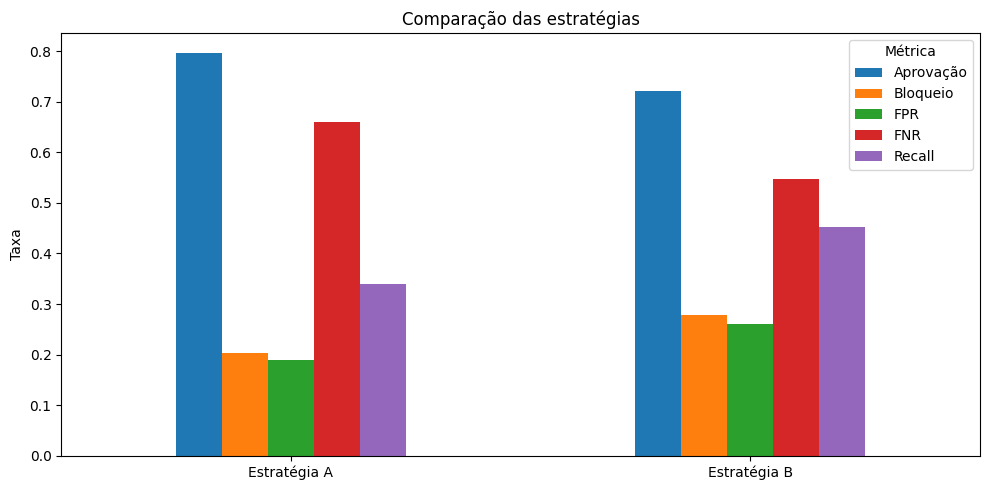

In [11]:
grafico = metricas.loc[['approval_rate','block_rate','FPR','FNR','recall']].copy()
grafico.index = ['Aprovação','Bloqueio','FPR','FNR','Recall']
ax = grafico.T.plot(kind='bar', figsize=(10,5))
ax.set_ylabel('Taxa')
ax.set_title('Comparação das estratégias')
ax.legend(title='Métrica')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Leitura executiva do exemplo

A estratégia B foi desenhada para ser mais sensível a sinais de risco. No dataset sintético, isso tende a aumentar a captura de fraude, mas também pode aumentar falsos positivos e reduzir aprovação.

A decisão de negócio não deve ser baseada em uma única métrica. Em uma aplicação real, os custos de fraude, margem, chargeback, revisão manual e perda de cliente precisam ser incorporados.

## 12. Conclusão e limitações

**Conclusão do exemplo:** a comparação demonstra como transformar regras antifraude em decisões mensuráveis e avaliar o trade-off entre FN e FP.

**Limitações:**
- dados públicos sintéticos;
- regras A/B demonstrativas;
- ausência de randomização de produção;
- custos financeiros hipotéticos;
- uma base histórica de pedidos liberados não deve ser tratada como legítimo confirmado sem desfecho posterior.

**Próxima evolução:** substituir o dataset sintético por uma base autorizada e anonimizada com desfecho posterior confiável, calibrar os limiares fora da amostra e avaliar estabilidade por período, canal e produto.